# **Redes Neuronales 2**
## Práctica 5: Aprendizaje de representaciones

**Temas:**
- Auto-codificadores clásicos y exploración del espacio latente.
- Auto-codificadores por eliminación de ruido (denoising).
- Auto-codificadores variacionales (VAE).
- Aprendizaje contrastivo (SimCLR simplificado) y sonda lineal.

Dataset: **FashionMNIST** (imágenes 28×28 de prendas, 10 clases).

In [ ]:
# Imports y configuración básica
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cpu


In [ ]:
# ya te crea el dataset

from torchvision.datasets import FashionMNIST
from torchvision import transforms

train_full = FashionMNIST("./data", train=True, transform=transforms.ToTensor(),
                          download=True)
clases = train_full.classes
Lt = int(len(train_full) * 0.8)
train_data, valid_data = random_split(train_full, [Lt, len(train_full) - Lt])
test_data = FashionMNIST("./data", train=False, transform=transforms.ToTensor(),
                         download=True)


In [4]:
train_data[0] #(imagen, etiqueta)
train_data[0][0].shape # (canal, x, y)

torch.Size([1, 28, 28])

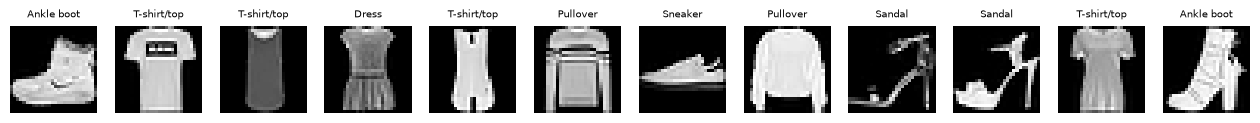

In [5]:
nbatch = 256
train_loader = DataLoader(train_data, batch_size=nbatch, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=nbatch)
test_loader = DataLoader(test_data, batch_size=nbatch)

fig, axs = plt.subplots(1, 12, figsize=(16, 2))
for k, ax in enumerate(axs):
    xk, yk = train_full[k]
    ax.imshow(xk.squeeze(), cmap="gray"); ax.set_title(clases[yk], fontsize=7)
    ax.axis("off")
plt.show()

## Parte 1: auto-codificador clásico

Implementamos un AE denso básico: el codificador comprime la imagen (784 píxeles) a un vector `z` de `emb_size` dimensiones; el decodificador la reconstruye. Completar los métodos `fit` y `test` (una época de entrenamiento y una evaluación).

In [14]:
class AE(nn.Module):
    def __init__(self, emb_size, lr=1e-3, imsize=(28, 28)):
        super().__init__()
        nin = imsize[0] * imsize[1]
        self.encoder = nn.Sequential(nn.Linear(nin, emb_size), nn.Sigmoid())
        self.decoder = nn.Sequential(nn.Linear(emb_size, nin), nn.Sigmoid())
        self.loss_func = nn.MSELoss()
        self.optim = torch.optim.Adam(self.parameters(), lr=lr)
        self.imsize = imsize
        self.to(device)

    def encode(self, x):
        return self.encoder(x.view(x.shape[0], -1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, *self.imsize)

    def forward(self, x):
        return self.decode(self.encode(x))

    def fit(self, loader):
        """Una época de entrenamiento; devuelve la pérdida media.""" #hace solo una epocaaa
        self.train()
        total, n = 0.0, 0
        for x, _ in loader:      # ¡no usamos las etiquetas!
            x = x.to(device)
            
            self.optim.zero_grad() #aca no puedo hacer self.modelo(x)
            out = self.forward(x)
            loss = self.loss_func(x, out)
            loss.backward()
            self.optim.step()

            total += loss.item() * len(x); n += len(x)
        return total / n

    @torch.no_grad() #decoramos el matodo
    def test(self, loader):
        self.eval()
        total, n = 0.0, 0
        for x, _ in loader: #recorro todo el loader dle test
            x = x.to(device)
            # ====================== COMPLETAR ======================
            # solo forward y pérdida (sin gradientes)
            x_pred = self.forward(x)
            loss = self.loss_func(x,x_pred)
            # ========================================================
            total += loss.item() * len(x); n += len(x)
        return total / n

def entrenar_ae(net, train_loader, valid_loader, epocas=8, verbose=True):
    log = {"train": [], "valid": []}
    for ep in range(epocas):
        log["train"].append(net.fit(train_loader))
        log["valid"].append(net.test(valid_loader))
        if verbose:
            print(f"época {ep+1}: train {log['train'][-1]:.4f} | valid {log['valid'][-1]:.4f}")
    return log

In [15]:
EMB_SIZE = 32
torch.manual_seed(SEED)
net = AE(emb_size=EMB_SIZE)
log = entrenar_ae(net, train_loader, valid_loader)

época 1: train 0.0938 | valid 0.0699
época 2: train 0.0620 | valid 0.0558
época 3: train 0.0505 | valid 0.0464
época 4: train 0.0429 | valid 0.0403
época 5: train 0.0378 | valid 0.0361
época 6: train 0.0343 | valid 0.0331
época 7: train 0.0315 | valid 0.0306
época 8: train 0.0294 | valid 0.0287


### Calidad de reconstrucción (provisto)

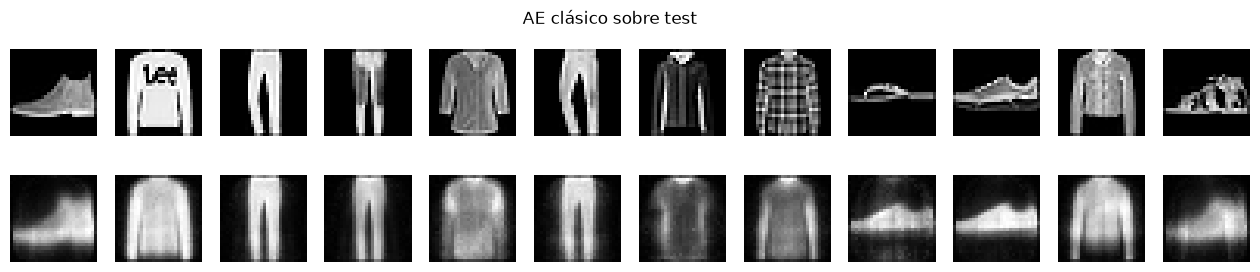

In [ ]:
def mostrar_reconstrucciones(net, loader, titulo="", ruido=0.0):
    net.eval()
    x, _ = next(iter(loader))
    if ruido > 0:
        x = torch.clamp(x + ruido * torch.randn(x.shape), 0, 1)
    with torch.no_grad():
        x_hat = net(x.to(device)).cpu()
    fig, axs = plt.subplots(2, 12, figsize=(16, 3))
    for k in range(12):
        axs[0, k].imshow(x[k].squeeze(), cmap="gray"); axs[0, k].axis("off")
        axs[1, k].imshow(x_hat[k].squeeze(), cmap="gray"); axs[1, k].axis("off")
    axs[0, 0].set_ylabel("x"); axs[1, 0].set_ylabel("x̂")
    fig.suptitle(titulo)
    plt.show()

mostrar_reconstrucciones(net, test_loader, "AE clásico sobre test")

### Exploración del espacio latente (provisto)

No alcanza con reconstruir: queremos que `z` capture la **estructura** de los datos. Proyectamos los códigos de test a 2D con **UMAP** (o PCA si no está disponible) y coloreamos por clase — que el AE nunca vio.

In [18]:
# En Colab hace falta instalar dependencias (local: ya instaladas)
import importlib, subprocess, sys
for pkg, mod in [('umap-learn', 'umap')]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

d:\facuult\REDES_NEURONALES_II\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
def codigos(net, loader, N=2000):
    zs, ys = [], [] #dominio
    net.eval() #model punto eval
    with torch.no_grad():
        for x, y in loader:
            zs.append(net.encode(x.to(device)).cpu()) #encode
            ys.append(y) #ponemos la categoria
            if sum(len(v) for v in ys) >= N: break #puede pasarse por batch
    return torch.cat(zs)[:N].numpy(), torch.cat(ys)[:N].numpy()

def plot_latente(z2d, labels, titulo=""):
    plt.figure(figsize=(7, 6))
    for l in np.unique(labels):
        m = labels == l
        plt.scatter(z2d[m, 0], z2d[m, 1], s=6, label=clases[l])
    plt.legend(markerscale=2, fontsize=8); plt.title(titulo); plt.show()



In [6]:
from umap import UMAP
from sklearn.decomposition import PCA

d:\facuult\REDES_NEURONALES_II\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


d:\facuult\REDES_NEURONALES_II\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


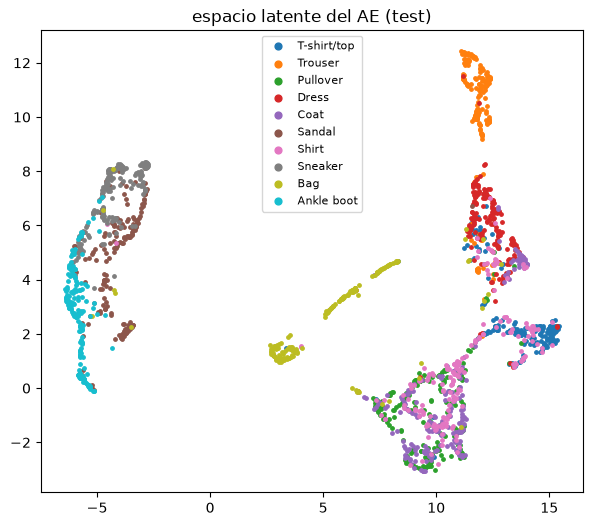

In [23]:
z_test, y_test = codigos(net, test_loader)
try:
    z2d = UMAP(n_components=2, random_state=SEED).fit_transform(z_test)
except ImportError:
    z2d = PCA(n_components=2).fit_transform(z_test)
plot_latente(z2d, y_test, "espacio latente del AE (test)")

---
### Ejercicio 1: explorar la arquitectura

Explorar cómo cambian reconstrucción y espacio latente al variar el diseño. Evaluar al menos **dos valores por variable**: tamaño del latente (`emb_size` ∈ {2, 32}) y profundidad del codificador (1 capa vs. 2 capas con una intermedia de 128). Comparar la pérdida de validación final en una tabla.

Vamos a probar diferentes vaores de embeding size y luego con mas capas

época 1: train 0.1605 | valid 0.1411
época 2: train 0.1225 | valid 0.1085
época 3: train 0.1012 | valid 0.0959
época 4: train 0.0921 | valid 0.0892
época 5: train 0.0863 | valid 0.0844
época 6: train 0.0821 | valid 0.0808
época 7: train 0.0789 | valid 0.0780
época 8: train 0.0765 | valid 0.0759
época 1: train 0.1269 | valid 0.0953
época 2: train 0.0881 | valid 0.0841
época 3: train 0.0811 | valid 0.0789
época 4: train 0.0756 | valid 0.0735
época 5: train 0.0711 | valid 0.0697
época 6: train 0.0678 | valid 0.0668
época 7: train 0.0651 | valid 0.0644
época 8: train 0.0629 | valid 0.0621
época 1: train 0.1088 | valid 0.0811
época 2: train 0.0744 | valid 0.0695
época 3: train 0.0651 | valid 0.0619
época 4: train 0.0585 | valid 0.0561
época 5: train 0.0530 | valid 0.0506
época 6: train 0.0476 | valid 0.0454
época 7: train 0.0429 | valid 0.0413
época 8: train 0.0393 | valid 0.0381
época 1: train 0.0920 | valid 0.0660
época 2: train 0.0581 | valid 0.0521
época 3: train 0.0471 | valid 0.0435
é

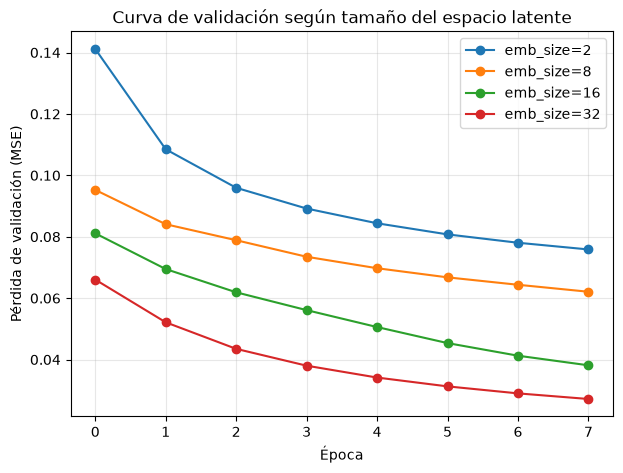

In [26]:
modelos = {}
hist = {}
sizes = [2,8,16,32]

for n in sizes:
    net = AE(emb_size = n)
    log = entrenar_ae(net, train_loader, valid_loader)

    modelos[n] = net
    hist[n] = log


plt.figure(figsize=(7, 5))
for n in sizes:
    plt.plot(hist[n]["valid"], label=f"emb_size={n}", marker="o")

plt.xlabel("Época")
plt.ylabel("Pérdida de validación (MSE)")
plt.title("Curva de validación según tamaño del espacio latente")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
    

entre mas agrande el el embedding menor error de reconstruccion logico

In [ ]:
class AE_profundo(nn.Module):
    def __init__(self, emb_size, hidden=[], lr=1e-3, imsize=(28, 28)):
        """
        hidden: lista con el tamaño de cada capa oculta.
                [] -> 1 capa (igual que el AE original)
                [128] -> 2 capas, con una intermedia de 128
                [256, 128] -> 3 capas, intermedias de 256 y 128
        """
        super().__init__()
        nin = imsize[0] * imsize[1]

        # --- armar encoder dinámicamente ---
        capas_enc = []
        tam_prev = nin
        for h in hidden:
            capas_enc.append(nn.Linear(tam_prev, h))
            capas_enc.append(nn.ReLU())
            tam_prev = h
        capas_enc.append(nn.Linear(tam_prev, emb_size))
        capas_enc.append(nn.Sigmoid())
        self.encoder = nn.Sequential(*capas_enc)

        # --- armar decoder dinámicamente (simétrico, invertido) ---
        capas_dec = []
        tam_prev = emb_size
        for h in reversed(hidden):
            capas_dec.append(nn.Linear(tam_prev, h))
            capas_dec.append(nn.ReLU())
            tam_prev = h
        capas_dec.append(nn.Linear(tam_prev, nin))
        capas_dec.append(nn.Sigmoid())
        self.decoder = nn.Sequential(*capas_dec)

        self.loss_func = nn.MSELoss()
        self.optim = torch.optim.Adam(self.parameters(), lr=lr)
        self.imsize = imsize
        self.to(device)

    def encode(self, x):
        return self.encoder(x.view(x.shape[0], -1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, *self.imsize)

    def forward(self, x):
        return self.decode(self.encode(x))

    def fit(self, loader):
        self.train()
        total, n = 0.0, 0
        for x, _ in loader:
            x = x.to(device)
            self.optim.zero_grad()
            out = self.forward(x)
            loss = self.loss_func(x, out)
            loss.backward()
            self.optim.step()
            total += loss.item() * len(x); n += len(x)
        return total / n

    @torch.no_grad()
    def test(self, loader):
        self.eval()
        total, n = 0.0, 0
        for x, _ in loader:
            x = x.to(device)
            x_pred = self.forward(x)
            loss = self.loss_func(x, x_pred)
            total += loss.item() * len(x); n += len(x)
        return total / n

época 1: train 0.0927 | valid 0.0704
época 2: train 0.0622 | valid 0.0561
época 3: train 0.0512 | valid 0.0474
época 4: train 0.0440 | valid 0.0415
época 5: train 0.0390 | valid 0.0372
época 6: train 0.0353 | valid 0.0340
época 7: train 0.0324 | valid 0.0314
época 8: train 0.0302 | valid 0.0295
época 1: train 0.0774 | valid 0.0494
época 2: train 0.0399 | valid 0.0320
época 3: train 0.0282 | valid 0.0260
época 4: train 0.0249 | valid 0.0244
época 5: train 0.0234 | valid 0.0230
época 6: train 0.0223 | valid 0.0221
época 7: train 0.0216 | valid 0.0214
época 8: train 0.0209 | valid 0.0208
época 1: train 0.0786 | valid 0.0583
época 2: train 0.0447 | valid 0.0406
época 3: train 0.0360 | valid 0.0310
época 4: train 0.0283 | valid 0.0266
época 5: train 0.0250 | valid 0.0244
época 6: train 0.0237 | valid 0.0235
época 7: train 0.0227 | valid 0.0224
época 8: train 0.0219 | valid 0.0217


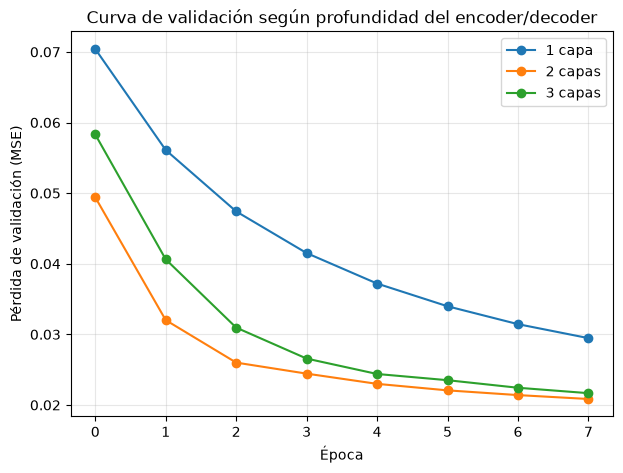

In [28]:
arquitecturas = {
    "1 capa":  [],
    "2 capas": [128],
    "3 capas": [256, 128],
}

modelos = {}
hist = {}

for nombre, hidden in arquitecturas.items():
    net = AE_profundo(emb_size=32, hidden=hidden)
    log = entrenar_ae(net, train_loader, valid_loader)
    modelos[nombre] = net
    hist[nombre] = log


plt.figure(figsize=(7, 5))
for nombre in arquitecturas:
    plt.plot(hist[nombre]["valid"], label=nombre, marker="o")
plt.xlabel("Época"); plt.ylabel("Pérdida de validación (MSE)")
plt.title("Curva de validación según profundidad del encoder/decoder")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

tampoco hay una correlacion entre capas y error

In [29]:
import umap
import matplotlib.pyplot as plt

def graficar_umap_multiple(modelos, loader, clases, N=2000):
    n_modelos = len(modelos)
    fig, axs = plt.subplots(1, n_modelos, figsize=(5*n_modelos, 5))
    if n_modelos == 1:
        axs = [axs]

    for ax, (nombre, net) in zip(axs, modelos.items()):
        zs, ys = codigos(net, loader, N=N)

        # si el latente ya es 2D, no hace falta UMAP
        if zs.shape[1] == 2:
            proy = zs
        else:
            reducer = umap.UMAP(n_components=2, random_state=42)
            proy = reducer.fit_transform(zs)

        scatter = ax.scatter(proy[:, 0], proy[:, 1], c=ys, cmap="tab10", s=8, alpha=0.7)
        ax.set_title(nombre)
        ax.set_xlabel("UMAP 1")
        ax.set_ylabel("UMAP 2")

    # leyenda de clases compartida
    handles, _ = scatter.legend_elements()
    fig.legend(handles, clases, loc="center right", bbox_to_anchor=(1.15, 0.5), title="Clase")
    plt.tight_layout()
    plt.show()

d:\facuult\REDES_NEURONALES_II\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\facuult\REDES_NEURONALES_II\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
d:\facuult\REDES_NEURONALES_II\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


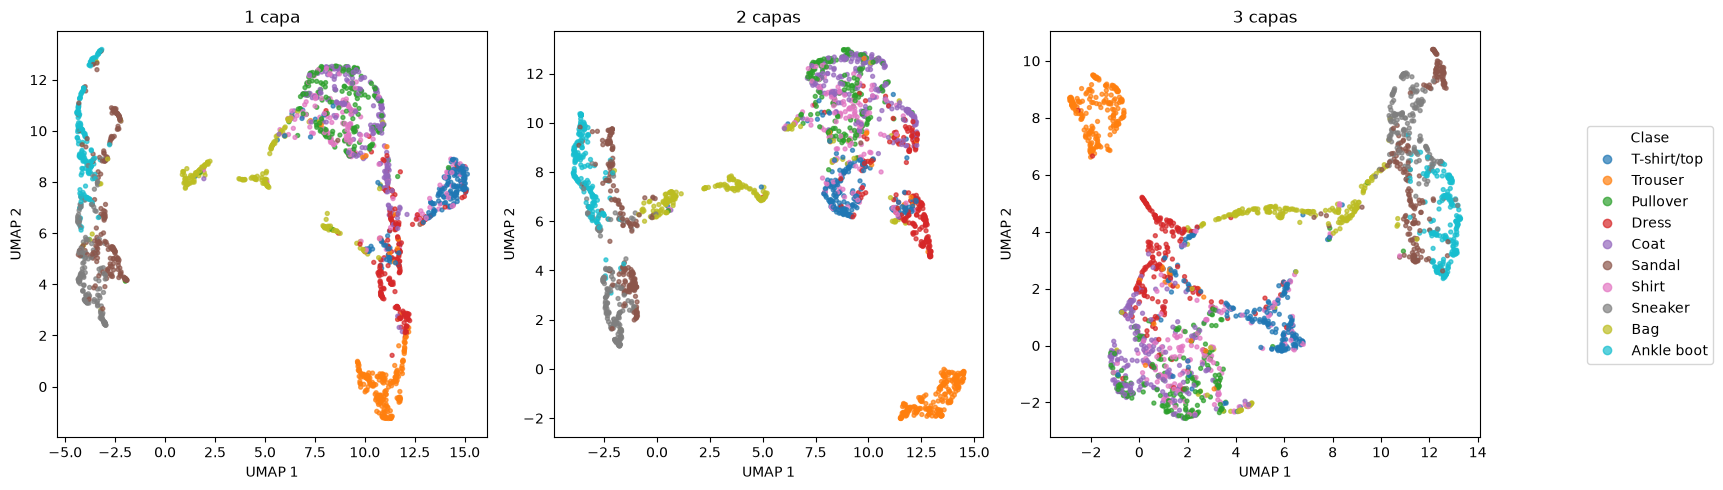

In [30]:
graficar_umap_multiple(modelos, valid_loader, clases)

---
### Ejercicio 2: auto-codificador por eliminación de ruido

Primero, evaluar la **robustez al ruido** del AE clásico: reconstruir imágenes de test corrompidas con ruido gaussiano (usar `mostrar_reconstrucciones(..., ruido=0.5)`). Luego implementar un **DAE**: durante el entrenamiento se corrompe la entrada pero se pide reconstruir la imagen **original**. Comparar ambos sobre test ruidoso, para distintas intensidades de ruido en train y test.

Ayuda: `x_ruidosa = torch.clamp(x + self.noise * torch.randn_like(x), 0, 1)`

Vamos a evaluar la robustez al ruido del AE clásico usando test con ruido

In [35]:
class AE(nn.Module):
    def __init__(self, emb_size, lr=1e-3, imsize=(28, 28), noise = 0.0):
        super().__init__()
        nin = imsize[0] * imsize[1]
        self.encoder = nn.Sequential(nn.Linear(nin, emb_size), nn.Sigmoid())
        self.decoder = nn.Sequential(nn.Linear(emb_size, nin), nn.Sigmoid())
        self.loss_func = nn.MSELoss()
        self.optim = torch.optim.Adam(self.parameters(), lr=lr)
        self.imsize = imsize
        self.to(device)
        self.noise = noise

    def encode(self, x):
        return self.encoder(x.view(x.shape[0], -1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, *self.imsize)

    def forward(self, x):
        return self.decode(self.encode(x))

    def fit(self, loader):
        """Una época de entrenamiento; devuelve la pérdida media.""" #hace solo una epocaaa
        self.train()
        total, n = 0.0, 0
        for x, _ in loader:      # ¡no usamos las etiquetas!
            x = x.to(device)
            x_ruidosa = torch.clamp(x + self.noise * torch.randn_like(x), 0, 1) #si es cero no cambia nada
            
            self.optim.zero_grad() #aca no puedo hacer self.modelo(x)
            out = self.forward(x_ruidosa) #solo cambia aca como hago el forward
            loss = self.loss_func(x, out)
            loss.backward()
            self.optim.step()

            total += loss.item() * len(x); n += len(x)
        return total / n

    @torch.no_grad() #decoramos el matodo
    def test(self, loader):
        self.eval()
        total, n = 0.0, 0
        for x, _ in loader: #recorro todo el loader dle test
            x = x.to(device)
            # ====================== COMPLETAR ======================
            # solo forward y pérdida (sin gradientes)
            x_pred = self.forward(x)
            loss = self.loss_func(x,x_pred)
            # ========================================================
            total += loss.item() * len(x); n += len(x)
        return total / n

def entrenar_ae(net, train_loader, valid_loader, epocas=8, verbose=True):
    log = {"train": [], "valid": []}
    for ep in range(epocas):
        log["train"].append(net.fit(train_loader))
        log["valid"].append(net.test(valid_loader))
        if verbose:
            print(f"época {ep+1}: train {log['train'][-1]:.4f} | valid {log['valid'][-1]:.4f}")
    return log



época 1: train 0.1685 | valid 0.1522
época 2: train 0.1289 | valid 0.1108
época 3: train 0.1021 | valid 0.0963
época 4: train 0.0924 | valid 0.0895
época 5: train 0.0865 | valid 0.0845
época 6: train 0.0821 | valid 0.0808
época 7: train 0.0789 | valid 0.0779
época 8: train 0.0763 | valid 0.0757
época 1: train 0.1671 | valid 0.1420
época 2: train 0.1219 | valid 0.1110
época 3: train 0.1033 | valid 0.0997
época 4: train 0.0957 | valid 0.0946
época 5: train 0.0922 | valid 0.0920
época 6: train 0.0903 | valid 0.0906
época 7: train 0.0893 | valid 0.0897
época 8: train 0.0886 | valid 0.0891


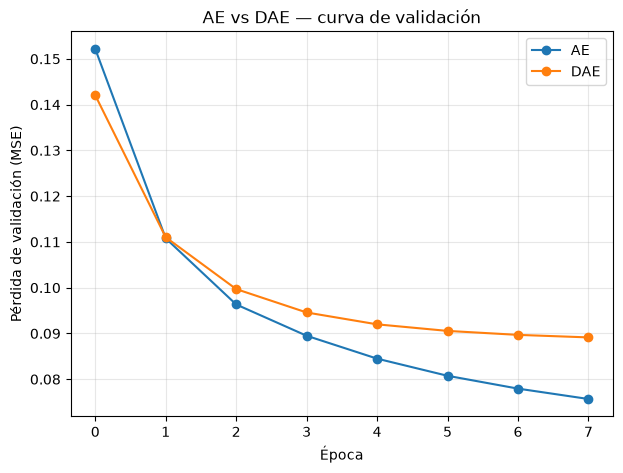

In [38]:
#pruebo dos modelos. Uno AE y otro DAE

ae = AE(emb_size = 2, noise = 0)
dae = AE(emb_size = 2, noise = 2)

log_ae = entrenar_ae(ae, train_loader, valid_loader, epocas=8, verbose=True)
log_dae = entrenar_ae(dae, train_loader, valid_loader, epocas=8, verbose=True)

plt.figure(figsize=(7, 5))
plt.plot(log_ae["valid"], label="AE", marker="o")
plt.plot(log_dae["valid"], label="DAE", marker="o")
plt.xlabel("Época")
plt.ylabel("Pérdida de validación (MSE)")
plt.title("AE vs DAE — curva de validación")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


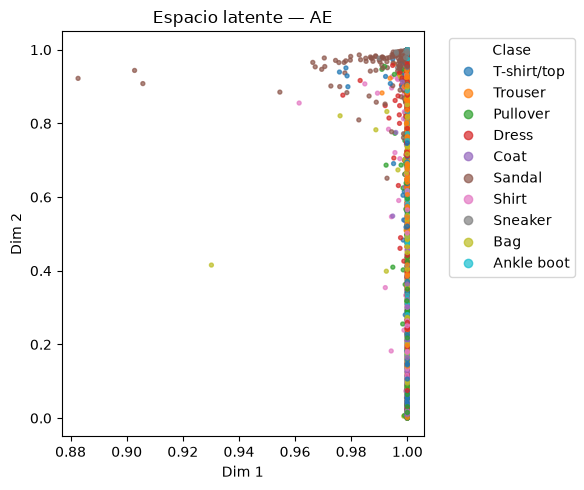

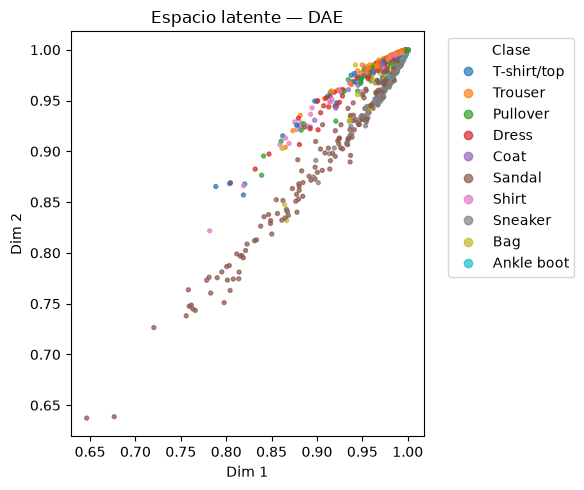

In [39]:
import umap

def graficar_umap(net, loader, clases, N=2000, titulo=""):
    zs, ys = codigos(net, loader, N=N)

    if zs.shape[1] == 2:
        proy = zs
    else:
        reducer = umap.UMAP(n_components=2, random_state=42)
        proy = reducer.fit_transform(zs)

    plt.figure(figsize=(6, 5))
    scatter = plt.scatter(proy[:, 0], proy[:, 1], c=ys, cmap="tab10", s=8, alpha=0.7)
    plt.title(titulo)
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")
    handles, _ = scatter.legend_elements()
    plt.legend(handles, clases, title="Clase", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

# figura 1: AE
graficar_umap(ae, valid_loader, clases, titulo="Espacio latente — AE")

# figura 2: DAE
graficar_umap(dae, valid_loader, clases, titulo="Espacio latente — DAE")

---
### Ejercicio 3: auto-codificador variacional

El VAE codifica cada imagen como una **distribución** $q(z|x)=\mathcal{N}(\mu(x), \sigma(x))$ y optimiza la **ELBO**: reconstrucción + término KL que empuja $q$ hacia $\mathcal{N}(0, I)$.

Completar en la clase `VAE`:
1. el **truco de reparametrización** ($z = \mu + \sigma \cdot \varepsilon$, $\varepsilon \sim \mathcal{N}(0,I)$),
2. el término **KL** de la pérdida — para gaussianas diagonales:
$$D_{KL} = -\tfrac{1}{2}\sum_j \big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big)$$

Luego entrenar con latente de dimensión 2 y explorar: reconstrucciones, el **mosaico generativo** (decodificar una grilla de $z$) y el scatter del latente.

In [47]:
class VAE(nn.Module):
    def __init__(self, latent_size=2, encoder_size=256, kl_beta=1.0, lr=1e-3,
                 imsize=(28, 28)):
        super().__init__()
        nin = imsize[0] * imsize[1]
        self.encoder = nn.Sequential(nn.Linear(nin, encoder_size), nn.ReLU())
        self.mu = nn.Linear(encoder_size, latent_size)
        self.logvar = nn.Linear(encoder_size, latent_size)   # log(σ²): sin restricción de signo


        self.decoder = nn.Sequential(nn.Linear(latent_size, encoder_size), nn.ReLU(),
                                     nn.Linear(encoder_size, nin), nn.Sigmoid())
        self.kl_beta = kl_beta
        self.imsize = imsize
        self.optim = torch.optim.Adam(self.parameters(), lr=lr)
        self.to(device)

        self.loss_func = nn.MSELoss(reduction="sum")

    def encode(self, x):
        h = self.encoder(x.view(x.shape[0], -1))
        return self.mu(h), self.logvar(h)

    def reparametrizar(self, mu, logvar): # Importante esto!
        sigma = torch.exp(0.5 * logvar)
        eps = torch.randn_like(sigma)
        return  mu + sigma * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, *self.imsize)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrizar(mu, logvar)
        return self.decode(z), mu, logvar

    def perdida(self, x, x_hat, mu, logvar): # Importante esto!
        rec = self.loss_func(x_hat, x) / len(x)
        kl = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / len(x)
        return rec + self.kl_beta * kl, rec, kl

    def fit(self, loader): # Esto ajusta 1 época
        self.train()
        tot = np.zeros(3); n = 0
        for x, _ in loader:
            x = x.to(device)
            self.optim.zero_grad()
            x_hat, mu, logvar = self.forward(x)
            loss, rec, kl = self.perdida(x, x_hat, mu, logvar)
            loss.backward()
            self.optim.step()
            tot += np.array([loss.item(), rec.item(), kl.item()]) * len(x); n += len(x)
        return tot / n

    @torch.no_grad()
    def test(self, loader):
        self.eval()
        tot = np.zeros(3); n = 0
        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = self.forward(x) #calculo forward
            loss, rec, kl = self.perdida(x, x_hat, mu, logvar) #la perdida
            tot += np.array([loss.item(), rec.item(), kl.item()]) * len(x); n += len(x)
        return tot / n

In [49]:
def entrenar_ae(net, train_loader, valid_loader, epocas=8, verbose=True):
    log = {"train": [], "valid": []}
    for ep in range(epocas):
        log["train"].append(net.fit(train_loader))
        log["valid"].append(net.test(valid_loader))
        #if verbose:
            #print(f"época {ep+1}: train {log['train'][-1]:.4f} | valid {log['valid'][-1]:.4f}")
    return log


vae = VAE()
log = entrenar_ae(vae, train_loader, valid_loader)

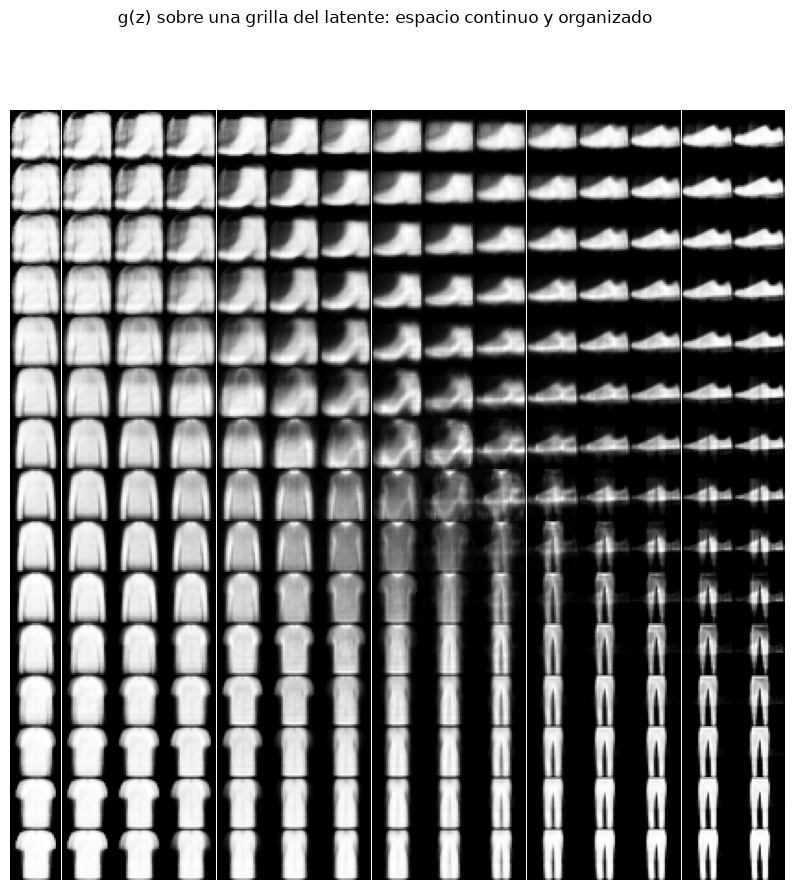

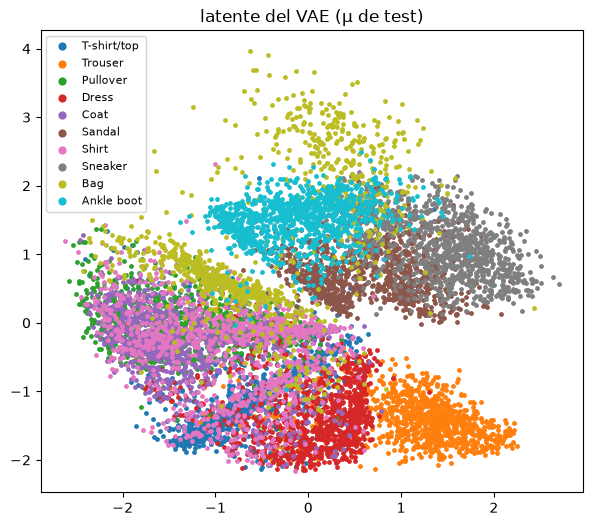

In [50]:
# mosaico generativo: decodificamos una grilla del espacio latente
N = 15
fig, axs = plt.subplots(N, N, figsize=(10, 10))
vae.eval()
with torch.no_grad():
    for i, zy in enumerate(np.linspace(2.5, -2.5, N)):
        for j, zx in enumerate(np.linspace(-2.5, 2.5, N)):
            z = torch.tensor([[zx, zy]], dtype=torch.float32).to(device)
            axs[i, j].imshow(vae.decode(z).cpu().squeeze(), cmap="gray")
            axs[i, j].axis("off")
plt.subplots_adjust(wspace=0, hspace=0)
plt.suptitle("g(z) sobre una grilla del latente: espacio continuo y organizado")
plt.show()

# scatter del latente para test
zs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, _ = vae.encode(x.to(device))
        zs.append(mu.cpu()); ys.append(y)
z_vae = torch.cat(zs).numpy(); y_vae = torch.cat(ys).numpy()
plot_latente(z_vae, y_vae, "latente del VAE (μ de test)")



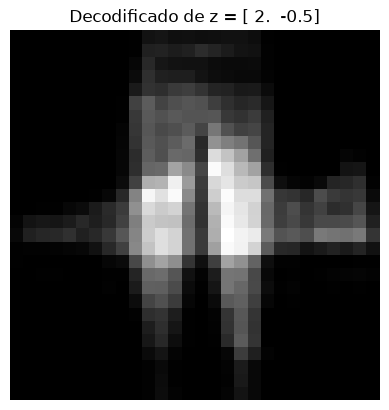

In [52]:
import torch
import matplotlib.pyplot as plt

vae.eval()
with torch.no_grad():
    z = torch.tensor([[2.0, -0.5]], device=device)  # el punto que elegiste del scatter
    img = vae.decode(z).cpu()

plt.imshow(img.squeeze(), cmap="gray")
plt.title(f"Decodificado de z = {z.cpu().numpy().flatten()}")
plt.axis("off")
plt.show()

---
### Ejercicio 4: aprendizaje contrastivo (SimCLR simplificado)

Otra forma de aprender representaciones **sin etiquetas**: acercar dos vistas aumentadas de la misma imagen (par **positivo**) y alejar el resto del batch (**negativos**), con la pérdida **InfoNCE**:
$$L = -\log \frac{\exp(s(z_i, z_j)/\tau)}{\sum_{k \neq i} \exp(s(z_i, z_k)/\tau)}$$
con $s$ = similitud coseno y $\tau$ = temperatura.

- a) Completar la pérdida `info_nce` (Va de regalo).
- b) Entrenar y evaluar con una **sonda lineal**: congelar el codificador y entrenar una capa lineal para clasificar. Comparar con la sonda sobre el AE del Ejercicio 1 y sobre píxeles crudos.

In [ ]:
# aumentaciones simples para 28x28 (provisto)
aug = transforms.Compose([
    transforms.RandomResizedCrop(28, scale=(0.5, 1.0), antialias=True),
    transforms.RandomHorizontalFlip(),
])

: 

In [ ]:
class Codificador(nn.Module):
    """CNN chica: produce features h (128d). El proyector z se usa SOLO para
    la pérdida contrastiva; la sonda lineal se evalúa sobre h (como en SimCLR)."""
    def __init__(self, dim_h=128, dim_z=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, dim_h), nn.ReLU())
        self.proyector = nn.Sequential(nn.Linear(dim_h, dim_h), nn.ReLU(),
                                       nn.Linear(dim_h, dim_z))
    def forward(self, x):
        h = self.features(x)
        return self.proyector(h)

In [ ]:
# a)
# info_nce (provisto)
def info_nce(z1, z2, tau=0.2):
    """z1, z2: (B, d) proyecciones de las dos vistas del mismo batch."""
    B = z1.shape[0]
    z = torch.cat([z1, z2], dim=0)                      # (2B, d)
    z = nn.functional.normalize(z, dim=1)               # similitud coseno
    sim = z @ z.T / tau
    sim.fill_diagonal_(-torch.inf)
    positivos = torch.cat([torch.arange(B, 2 * B), torch.arange(0, B)]).to(z.device)
    return nn.functional.cross_entropy(sim, positivos)

# entrenamiento contrastivo (provisto)
class ParDeVistas(Dataset):
    # Devuelve DOS vistas aumentadas independientes de cada imagen.
    # Importante: la augmentation se aplica POR MUESTRA (no por batch),
    # para que cada imagen reciba un recorte/espejo distinto.
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        x, _ = self.base[i]
        return aug(x), aug(x)

par_loader = DataLoader(ParDeVistas(train_data), batch_size=256, shuffle=True,
                        num_workers=2)

torch.manual_seed(SEED)
enc = Codificador().to(device)
opt = torch.optim.Adam(enc.parameters(), lr=1e-3)
for ep in range(25):
    tot, n = 0.0, 0
    for v1, v2 in par_loader:
        v1, v2 = v1.to(device), v2.to(device)
        opt.zero_grad()
        loss = info_nce(enc(v1), enc(v2))
        loss.backward()
        opt.step()
        tot += loss.item() * len(v1); n += len(v1)
    if (ep + 1) % 5 == 0:
        print(f"época {ep+1}: InfoNCE {tot/n:.4f}")

In [ ]:
# b)
# ====================== COMPLETAR ======================
# ========================================================